# O passeio aleatório do zero

**Lances de moeda, a deriva que puxa o preço, os padrões que o acaso inventa, a ruína do jogador, o teste de Lo & MacKinlay no Ibovespa e quantos anos a bolsa precisa para mostrar que vence o CDI**

Gabriel Pires · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026

---

Some 1.000 lances de uma moeda justa a partir de \$100 e o preço **sobe até \$125, despenca até \$86 e bate uma nova máxima de \$131**. Parece tendência, queda e recuperação; a moeda nunca mudou. Dê a ela a vantagem do cassino, 19 em 37, e 1.000 preços que andam 4.000 passos terminam com **só 4 % abaixo do início**. O vídeo mostra isso em 12 linhas de Python. Este notebook reproduz cada número dele e vai além:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`passeio.py`), linha por linha, e um `assert` para cada número do vídeo |
| 1 | Um lance, um passo: a deriva e o risco de um passo, eqs. (1) e (2) |
| 2 | Somar lances: média $n\mu$ e desvio $\sigma\sqrt{n}$, eq. (3) |
| 3 | Os padrões são ilusão: arco-seno, reflexão e a maior sequência, eqs. (4) a (6) |
| 4 | A moeda com vantagem: 1.000 preços, 4.000 passos e a linha da deriva |
| 5 | Abaixo do início: binomial exata contra a normal, eq. (7) |
| 6 | A corrida: por que a deriva passa na frente em 1.368 passos, eq. (8) |
| 7 | A ruína do jogador: apostar pouco contra a casa é o pior, eq. (9) |
| 8 | 🇧🇷 O Ibovespa é um passeio aleatório? O teste de Lo & MacKinlay (1988), eqs. (10) e (11) |
| 9 | 💼 **Investidor:** Ibovespa contra o CDI como deriva + ruído, eq. (12) |
| 10 | 🏦 **Mesa:** 52 % de acerto é habilidade ou sorte? Custo e tamanho da posição |
| 11 | O que este modelo não vê + exercícios |

**Dados:** as seções 0 a 7 são simulação (a semente 52 da tela e moedas). As seções 8 e 9 usam dados **reais**: o fechamento diário do Ibovespa (`^BVSP`, Yahoo Finance) e o CDI diário (série 12 do SGS, Banco Central), de 02/01/1995 a 16/10/2026, em `dados/`.

> O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 12 linhas que aparecem digitadas no vídeo. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
rng = np.random.default_rng(52)     # moeda simulada
cara = rng.random(1000) < 0.5        # uma moeda justa
passo = np.where(cara, 1, -1)       # sobe ou desce $1
preco = 100 + passo.cumsum()        # o passeio aleatório
p = 19 / 37                         # a vantagem do cassino
deriva = p * 1 + (1 - p) * -1       # +2,7 centavos
sobe = rng.random((1000, 4000)) < p  # 1.000 preços
passeios = np.where(sobe, 1, -1).cumsum(axis=1)
abaixo = (passeios < 0).mean(axis=0)  # abaixo do início
print(preco.max(), preco.min(), preco[-1])
print(round(deriva, 4), abaixo[[24, 999, 3999]])

131 86 128
0.027 [0.426 0.204 0.042]


### Conferência: cada número que o vídeo mostra ou fala

O pico de \$125 vem antes do fundo de \$86, e a nova máxima de \$131 vem depois. `preco[k]` é o preço depois do lance $k+1$ (o array começa no primeiro lance). Os percentuais falados (43, 20 e 4 %) são os simulados arredondados.

In [2]:
i_fundo = int(preco.argmin()); i_pico = int(preco[:i_fundo].argmax()); i_max = int(preco.argmax())
sigma = float(np.sqrt(1 - deriva ** 2))
n_cruza = (sigma / deriva) ** 2
v = lambda x, d=1: f"{x:.{d}f}".replace(".", ",")
print(f"pico ${preco[i_pico]} em preco[{i_pico}] · fundo ${preco[i_fundo]} em preco[{i_fundo}] · nova máxima ${preco[i_max]} em preco[{i_max}] · fecha em ${preco[-1]}")
print(f"sobe 19/37 = {v(100 * p)} % · desce 18/37 = {v(100 * (1 - p))} % · deriva {v(100 * deriva, 2)} centavos por passo")
print(f"linha da deriva depois de 4.000 passos: +${v(4000 * deriva)}")
print(f"abaixo do início: {v(100 * abaixo[24])} % (25 passos), {v(100 * abaixo[999])} % (1.000), {v(100 * abaixo[3999])} % (4.000)")
print(f"cruzamento deriva × aleatoriedade: n* = (σ/μ)² = {v(n_cruza, 4)} passos")

assert (preco[i_pico], preco[i_fundo], preco[i_max], preco[-1]) == (125, 86, 131, 128)
assert i_pico < i_fundo < i_max and (i_pico, i_fundo, i_max) == (218, 485, 972)
assert len(cara) == 1000 and passeios.shape == (1000, 4000)                 # 1.000 lances; 1.000 preços × 4.000 passos
assert set(np.unique(passo)) == {-1, 1}                                      # cara +$1, coroa −$1
assert round(100 * p, 1) == 51.4 and round(100 * (1 - p), 1) == 48.6       # 19/37 e 18/37
assert round(100 * deriva, 1) == 2.7 and abs(deriva - 1 / 37) < 1e-15       # +2,7 centavos (é 1/37)
assert round(4000 * deriva) == 108                                          # linha da deriva: +$108
assert [round(100 * float(a)) for a in abaixo[[24, 999, 3999]]] == [43, 20, 4]
assert [round(100 * float(a), 1) for a in abaixo[[24, 999, 3999]]] == [42.6, 20.4, 4.2]
assert round(n_cruza) == 1368 and round(n_cruza, -2) == 1400               # "cerca de 1.400 passos"

pico $125 em preco[218] · fundo $86 em preco[485] · nova máxima $131 em preco[972] · fecha em $128
sobe 19/37 = 51,4 % · desce 18/37 = 48,6 % · deriva 2,70 centavos por passo
linha da deriva depois de 4.000 passos: +$108,1
abaixo do início: 42,6 % (25 passos), 20,4 % (1.000), 4,2 % (4.000)
cruzamento deriva × aleatoriedade: n* = (σ/μ)² = 1368,0000 passos


### Bibliotecas e estilo dos gráficos

In [3]:
import math
import pandas as pd
import matplotlib.pyplot as plt

NAVY, BLUE, LIGHT, RED, GREEN, GREY, GOLD, AMBER = "#1B2A4A", "#1E56B8", "#5B8DEF", "#B42318", "#1B7A4A", "#6B7590", "#B7791F", "#F2B544"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "$125 ... $86" é dinheiro, não fórmula
})
br = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
pct = lambda v, d=1: br(100 * v, d) + " %"
usd = lambda v, d=0: "$" + br(v, d)
brl = lambda v, d=0: ("−" if v < 0 else "") + "R$ " + br(abs(v), d)
fmt = dict(decimal=",", thousands=".")
fp = lambda d=1: (lambda v: f"{100 * v:.{d}f} %")       # formatador de tabela (o Styler troca o ponto pela vírgula): 42,6 %

Phi =lambda x: 0.5 * (1 + math.erf(x / math.sqrt(2)))     # normal acumulada, sem scipy

def Phi_inv(u, lo=-10.0, hi=10.0):                         # quantil da normal por bisseção
    for _ in range(100):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if Phi(mid) < u else (lo, mid)
    return (lo + hi) / 2

def binom_cauda(k, n, q):                                  # P(K >= k), K ~ Binomial(n, q), exata em escala log
    ks = np.arange(max(k, 0), n + 1)
    if len(ks) == 0:
        return 0.0
    lp = np.array([math.lgamma(n + 1) - math.lgamma(j + 1) - math.lgamma(n - j + 1) for j in ks]) + ks * math.log(q) + (n - ks) * math.log(1 - q)
    return float(np.exp(lp).sum())

Z95, Z975 = Phi_inv(0.95), Phi_inv(0.975)
print(f"z(95 %) = {Z95:.4f} · z(97,5 %) = {Z975:.4f}")

z(95 %) = 1.6449 · z(97,5 %) = 1.9600


## 1. Um lance, um passo — eqs. (1) e (2)

Cada lance é uma variável aleatória $X$ que vale $+1$ com probabilidade $p$ e $-1$ com probabilidade $1-p$. A **deriva** é o valor esperado de um passo, a mesma fórmula do vídeo do valor esperado (a roleta com 19 casas a favor em 37):

$$
\mu = \mathbb{E}[X] = p\cdot(+1) + (1-p)\cdot(-1) = 2p - 1 \tag{1}
$$

O **risco** de um passo é o seu desvio-padrão. Como $X^2 = 1$ sempre:

$$
\sigma^2 = \mathbb{E}[X^2] - \mu^2 = 1 - \mu^2 \tag{2}
$$

Na moeda justa, $\mu = 0$ e $\sigma = 1$. Na moeda do cassino, $\mu = 1/37$: o empurrão é **37 vezes menor** que o passo, e o risco quase não muda ($\sigma^2 = 1368/1369$).

In [4]:
moedas = {"moeda justa": 0.5, "a favor (19/37, a casa)": 19 / 37, "contra (18/37, o apostador no vermelho)": 18 / 37}
linhas = []
for nome, q in moedas.items():
    mu = 2 * q - 1                                    # (1)
    linhas.append({"moeda": nome, "p": q, "deriva μ (1)": mu, "σ² (2)": 1 - mu ** 2, "σ": math.sqrt(1 - mu ** 2), "σ/|μ|": math.sqrt(1 - mu ** 2) / abs(mu) if mu else None})
display(pd.DataFrame(linhas).style.format({"p": "{:.4f}", "deriva μ (1)": lambda x: f"{x:+.5f}" if x else "0", "σ² (2)": "{:.6f}", "σ": "{:.6f}", "σ/|μ|": "{:.2f}"}, na_rep="—", **fmt).hide(axis="index"))
assert abs((1 - deriva ** 2) - 1368 / 1369) < 1e-15 and abs(sigma / deriva - math.sqrt(1368)) < 1e-9

moeda,p,deriva μ (1),σ² (2),σ,σ/|μ|
moeda justa,"0,5000",0,"1,000000","1,000000",—
"a favor (19/37, a casa)","0,5135","+0,02703","0,999270","0,999635","36,99"
"contra (18/37, o apostador no vermelho)","0,4865","-0,02703","0,999270","0,999635","36,99"


## 2. Somar lances: o passeio — eq. (3)

O preço depois de $n$ lances é $100 + S_n$, com $S_n = X_1 + \cdots + X_n$. Como os lances são independentes, as médias somam e **as variâncias somam**:

$$
\mathbb{E}[S_n] = n\,\mu, \qquad \mathrm{DP}[S_n] = \sigma\sqrt{n} \tag{3}
$$

A média cresce com $n$; o desvio, só com $\sqrt{n}$. É a mesma corrida do vídeo do valor esperado, e ela decide tudo daqui para frente.

Na moeda justa, depois de 1.000 lances o desvio é $\sqrt{1000} \approx 31{,}6$: o preço termina, tipicamente, entre \$68 e \$132. O passeio da tela terminou em \$128, a 0,89 desvio do início. Nada de especial.

Um detalhe que o vídeo não conta: a moeda justa da tela deu **514 caras em 1.000**, ou 51,4 %. É exatamente a frequência da moeda do cassino (19/37 = 51,4 %). Com 1.000 lances, a moeda justa e a moeda com vantagem são indistinguíveis.

caras: 514 de 1.000 (51,4 %) · erro-padrão de uma frequência em 1.000 lances: 1,58 pontos
preço final $128 = 100 + 28: 0,89 desvio-padrão (3) do início
a moeda do cassino, em 1.000 passos, levaria em média a +$27,0; a moeda justa da tela foi a +$28


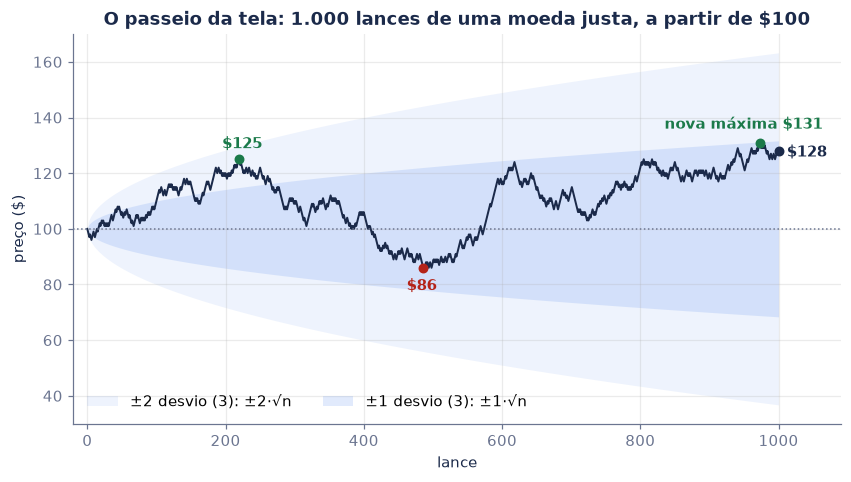

In [5]:
n = np.arange(1, 1001)
caras = int(cara.sum())
z_final = (preco[-1] - 100) / math.sqrt(1000)
print(f"caras: {caras} de 1.000 ({br(caras / 10, 1)} %) · erro-padrão de uma frequência em 1.000 lances: {br(100 * math.sqrt(0.25 / 1000), 2)} pontos")
print(f"preço final ${preco[-1]} = 100 + {preco[-1] - 100}: {br(z_final, 2)} desvio-padrão (3) do início")
print(f"a moeda do cassino, em 1.000 passos, levaria em média a +${br(1000 * deriva, 1)}; a moeda justa da tela foi a +${preco[-1] - 100}")
assert caras == 514 and round(z_final, 2) == 0.89

fig, ax = plt.subplots()
for k, a in [(2, 0.10), (1, 0.18)]:
    ax.fill_between(n, 100 - k * np.sqrt(n), 100 + k * np.sqrt(n), color=LIGHT, alpha=a, lw=0, label=f"±{k} desvio (3): ±{k}·√n")
ax.plot(np.r_[0, n], np.r_[100, preco], color=NAVY, lw=1.3)
ax.axhline(100, color=GREY, ls=":", lw=1)
for i, txt, c, xy in [(i_pico, "$125", GREEN, (195, 129)), (i_fundo, "$86", RED, (462, 78)), (i_max, "nova máxima $131", GREEN, (835, 136)), (999, "$128", NAVY, (1012, 126))]:
    ax.scatter([i + 1], [preco[i]], color=c, zorder=3, s=30); ax.annotate(txt, (i + 1, preco[i]), xy, color=c, weight="bold")
ax.set(title="O passeio da tela: 1.000 lances de uma moeda justa, a partir de $100", xlabel="lance", ylabel="preço ($)", ylim=(30, 170), xlim=(-20, 1090))
ax.legend(frameon=False, loc="lower left", ncol=2); plt.show()

## 3. Os padrões são ilusão — eqs. (4) a (6)

O passeio da tela "parece uma tendência, uma queda e uma recuperação". Quão raro é isso numa moeda justa? Simule 20.000 passeios justos de 1.000 lances e meça quatro coisas, no passeio da tela e em cada simulado.

**(a) Quanto tempo o preço passa acima do início.** A intuição diz "metade". A matemática diz o contrário: a fração $F_n$ do tempo acima de zero segue, para $n$ grande, a **lei do arco-seno** (Feller, 1968, cap. III):

$$
\Pr\!\left(F_n \le x\right) \;\longrightarrow\; \frac{2}{\pi}\arcsin\sqrt{x} \tag{4}
$$

A densidade é $1/(\pi\sqrt{x(1-x)})$, em forma de U: **meio a meio é o resultado menos provável**, e passar quase todo o tempo de um lado só é o mais provável. Um passeio justo parece ter "lado".

**(b) A máxima.** Pelo **princípio da reflexão**, para $a \ge 1$, os caminhos que tocam $a$ e terminam abaixo dele estão em bijeção com os que terminam acima (reflita o trecho depois do primeiro toque):

$$
\Pr\!\Big(\max_{k\le n} S_k \ge a\Big) = \Pr(S_n \ge a) + \Pr(S_n > a) \;\approx\; 2\left[1 - \Phi\!\left(\frac{a}{\sqrt{n}}\right)\right] \tag{5}
$$

**(c) A maior queda** (do pico ao fundo), só por simulação.

**(d) A maior sequência de lances iguais.** Ela cresce devagar, como o logaritmo (Erdős e Rényi, 1970; Schilling, 1990):

$$
\frac{R_n}{\log_2 n} \;\longrightarrow\; 1 \tag{6}
$$

Em 1.000 lances, $\log_2 1000 \approx 10$: uma sequência de 10 caras seguidas não é sinal de nada.

passeio da tela: 82,2 % do tempo acima de $100 · máxima +$31 · maior queda $39 · maior sequência 11 lances iguais


o que,teoria,simulação
"acima do início ≥ 82,2 % do tempo","27,7 % (arco-seno, 4)","27,9 %"
máxima ≥ +$31,"32,7 % (reflexão, 5)","32,9 %"
queda ≥ $39 do pico ao fundo,—,"42,5 %"
sequência ≥ 11 lances iguais,"log₂ 1000 = 10,0 (6)","38,9 %"


meio a meio (40 % a 60 % do tempo acima): 12,8 % pelo arco-seno, 12,8 % na simulação
quase tudo de um lado (< 10 % ou > 90 %): 41,0 % pelo arco-seno, 40,3 % na simulação
máxima: aproximação normal de (5) = 32,7 % · maior sequência média = 10,31 · maior queda mediana = $35
máxima média: $24,8 na simulação; √(2n/π) = $25,2


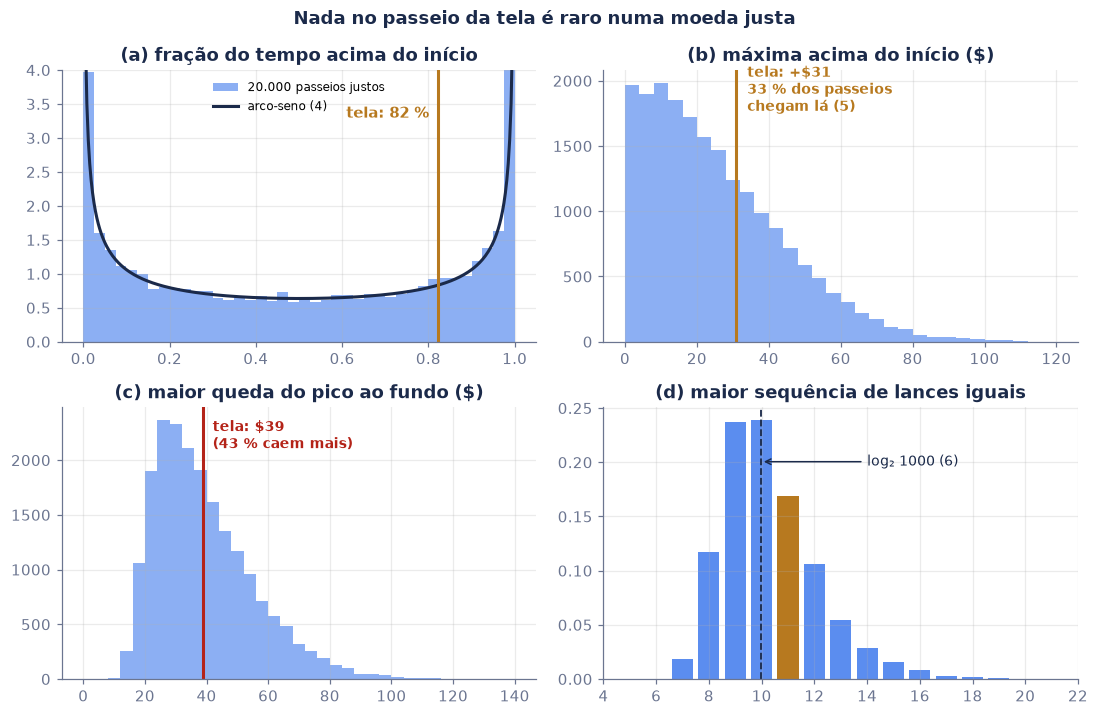

In [6]:
rng_p = np.random.default_rng(1)                    # outra semente: não mexe nos números da tela
N_SIM = 20_000
X = 2 * rng_p.integers(0, 2, size=(N_SIM, 1000), dtype=np.int8) - 1   # +1 ou −1
S = X.cumsum(axis=1, dtype=np.int16)
S0 = np.hstack([np.zeros((N_SIM, 1), np.int16), S])  # com o ponto de partida

def padroes(S0, X):
    acima = ((S0[:, 1:] > 0) | (S0[:, :-1] > 0)).mean(axis=1)          # convenção de Feller: o trecho (k−1, k) está acima
    maxima = S0.max(axis=1)
    queda = (np.maximum.accumulate(S0, axis=1) - S0).max(axis=1)
    corrida, maior = np.ones(len(X), np.int16), np.ones(len(X), np.int16)
    for j in range(1, X.shape[1]):
        corrida = np.where(X[:, j] == X[:, j - 1], corrida + 1, 1)
        maior = np.maximum(maior, corrida)
    return acima, maxima, queda, maior

f_sim, m_sim, q_sim, r_sim = padroes(S0, X)
f_tela, m_tela, q_tela, r_tela = [float(v[0]) for v in padroes(np.r_[0, preco - 100][None, :], passo[None, :])]
print(f"passeio da tela: {pct(f_tela)} do tempo acima de $100 · máxima +${m_tela:.0f} · maior queda ${q_tela:.0f} · maior sequência {r_tela:.0f} lances iguais")

arco = lambda x: 2 / math.pi * math.asin(math.sqrt(x))                                    # (4)
P_f = 1 - arco(f_tela)
P_m = binom_cauda(math.ceil((1000 + m_tela) / 2), 1000, 0.5) + binom_cauda(math.floor((1000 + m_tela) / 2) + 1, 1000, 0.5)   # (5) exata
tab = pd.DataFrame([
    {"o que": f"acima do início ≥ {pct(f_tela)} do tempo", "teoria": f"{pct(P_f)} (arco-seno, 4)", "simulação": pct((f_sim >= f_tela).mean())},
    {"o que": f"máxima ≥ +${m_tela:.0f}", "teoria": f"{pct(P_m)} (reflexão, 5)", "simulação": pct((m_sim >= m_tela).mean())},
    {"o que": f"queda ≥ ${q_tela:.0f} do pico ao fundo", "teoria": "—", "simulação": pct((q_sim >= q_tela).mean())},
    {"o que": f"sequência ≥ {r_tela:.0f} lances iguais", "teoria": f"log₂ 1000 = {br(math.log2(1000), 1)} (6)", "simulação": pct((r_sim >= r_tela).mean())},
])
display(tab.style.hide(axis="index").set_caption("Numa moeda justa, com 1.000 lances: com que frequência acontece algo tão 'forte' quanto no passeio da tela?"))
print(f"meio a meio (40 % a 60 % do tempo acima): {pct(arco(0.6) - arco(0.4))} pelo arco-seno, {pct(((f_sim >= 0.4) & (f_sim <= 0.6)).mean())} na simulação")
print(f"quase tudo de um lado (< 10 % ou > 90 %): {pct(2 * arco(0.1))} pelo arco-seno, {pct(((f_sim < 0.1) | (f_sim > 0.9)).mean())} na simulação")
print(f"máxima: aproximação normal de (5) = {pct(2 * (1 - Phi(m_tela / math.sqrt(1000))))} · maior sequência média = {br(r_sim.mean(), 2)} · maior queda mediana = ${np.median(q_sim):.0f}")
print(f"máxima média: ${br(m_sim.mean(), 1)} na simulação; √(2n/π) = ${br(math.sqrt(2 * 1000 / math.pi), 1)}")
assert (m_tela, q_tela, r_tela) == (31, 39, 11) and abs(P_m - (m_sim >= 31).mean()) < 0.015 and abs(P_f - (f_sim >= f_tela).mean()) < 0.015

fig, axs = plt.subplots(2, 2, figsize=(10, 6.6))
ax = axs[0, 0]
ax.hist(f_sim, bins=40, range=(0, 1), density=True, color=LIGHT, alpha=0.7, label="20.000 passeios justos")
xs = np.linspace(0.005, 0.995, 300); ax.plot(xs, 1 / (math.pi * np.sqrt(xs * (1 - xs))), color=NAVY, lw=2, label="arco-seno (4)")
ax.axvline(f_tela, color=GOLD, lw=2); ax.text(f_tela - 0.02, 3.3, f"tela: {pct(f_tela, 0)}", color=GOLD, ha="right", weight="bold")
ax.set(title="(a) fração do tempo acima do início", ylim=(0, 4)); ax.legend(frameon=False, fontsize=8, loc="upper center")
ax = axs[0, 1]
ax.hist(m_sim, bins=np.arange(0, 121, 4), color=LIGHT, alpha=0.7); ax.axvline(m_tela, color=GOLD, lw=2)
ax.text(m_tela + 3, ax.get_ylim()[1] * 0.85, f"tela: +${m_tela:.0f}\n{pct(P_m, 0)} dos passeios\nchegam lá (5)", color=GOLD, weight="bold", fontsize=9)
ax.set(title="(b) máxima acima do início ($)")
ax = axs[1, 0]
ax.hist(q_sim, bins=np.arange(0, 141, 4), color=LIGHT, alpha=0.7); ax.axvline(q_tela, color=RED, lw=2)
ax.text(q_tela + 3, ax.get_ylim()[1] * 0.85, f"tela: ${q_tela:.0f}\n({pct((q_sim >= q_tela).mean(), 0)} caem mais)", color=RED, weight="bold", fontsize=9)
ax.set(title="(c) maior queda do pico ao fundo ($)")
ax = axs[1, 1]
vals, cont = np.unique(r_sim, return_counts=True)
ax.bar(vals, cont / N_SIM, color=[GOLD if v == r_tela else LIGHT for v in vals]); ax.axvline(math.log2(1000), color=NAVY, ls="--", lw=1.2)
ax.annotate("log₂ 1000 (6)", (math.log2(1000), ax.get_ylim()[1] * 0.8), (14, ax.get_ylim()[1] * 0.8), color=NAVY, fontsize=9, va="center", arrowprops=dict(arrowstyle="->", color=NAVY, lw=1))
ax.set(title="(d) maior sequência de lances iguais", xlim=(4, 22))
fig.suptitle("Nada no passeio da tela é raro numa moeda justa", color=NAVY, weight="bold"); fig.tight_layout(); plt.show()

**Leitura.** O passeio da tela passou 82 % do tempo acima de \$100; numa moeda justa, isso ou mais acontece em mais de um quarto dos passeios, e "meio a meio" (entre 40 % e 60 % do tempo) só em 13 %. Uma máxima de +\$31 aparece em um terço deles; uma queda de \$39 do pico ao fundo, em 4 de cada 10 (a queda mediana é \$35); e 11 lances iguais seguidos, em 4 de cada 10. O "padrão" é o que o acaso faz. Por isso a regra da casa: antes de dar nome a um movimento, pergunte com que frequência uma moeda o produz.

## 4. A moeda com vantagem: a deriva

Agora $p = 19/37$, e cada passo tem deriva $\mu = 1/37 \approx 0{,}027$. Os 1.000 preços do código da tela andam 4.000 passos cada. Pela eq. (3), depois de 4.000 passos a média é $4000/37 = \$108{,}1$ e o desvio é $\sigma\sqrt{4000} \approx \$63{,}2$: **o espalhamento é do mesmo tamanho que a deriva**.

final médio dos 1.000 preços: +$105,3 (deriva: +$108,1), diferença de −1,40 erros-padrão (erro-padrão $2,02)
desvio dos finais: $63,9 (teoria (3): $63,2) · do mais baixo ao mais alto: −$110 a +$308
a média dos 1.000 caminhos fica a no máximo $5,0 da linha da deriva


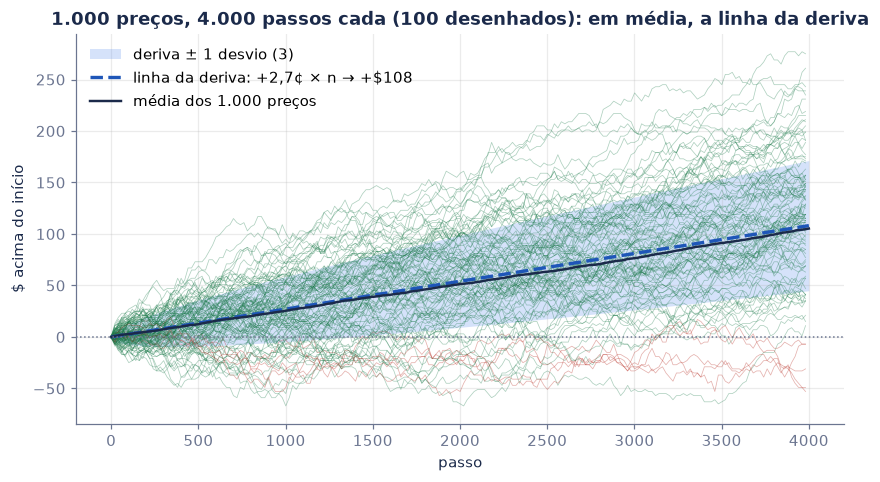

In [7]:
finais = passeios[:, -1]
ep = finais.std(ddof=1) / math.sqrt(len(finais))
print(f"final médio dos 1.000 preços: +${br(finais.mean(), 1)} (deriva: +${br(4000 * deriva, 1)}), diferença de {br((finais.mean() - 4000 * deriva) / ep, 2)} erros-padrão (erro-padrão ${br(ep, 2)})")
print(f"desvio dos finais: ${br(finais.std(ddof=1), 1)} (teoria (3): ${br(sigma * math.sqrt(4000), 1)}) · do mais baixo ao mais alto: −${-finais.min()} a +${finais.max()}")
media_caminho = passeios.mean(axis=0)
print(f"a média dos 1.000 caminhos fica a no máximo ${br(np.abs(media_caminho - deriva * np.arange(1, 4001)).max(), 1)} da linha da deriva")
assert abs(finais.mean() - 4000 * deriva) < 2 * ep and abs(finais.std() / (sigma * math.sqrt(4000)) - 1) < 0.05

fig, ax = plt.subplots()
t = np.arange(1, 4001)
for w in passeios[::10]:
    ax.plot(t[::20], w[::20], color=GREEN if w[-1] >= 0 else RED, lw=0.5, alpha=0.35)
ax.fill_between(t, deriva * t - sigma * np.sqrt(t), deriva * t + sigma * np.sqrt(t), color=LIGHT, alpha=0.25, lw=0, label="deriva ± 1 desvio (3)")
ax.plot(t, deriva * t, color=BLUE, lw=2.2, ls="--", label=f"linha da deriva: +2,7¢ × n → +${4000 * deriva:.0f}")
ax.plot(t, media_caminho, color=NAVY, lw=1.6, label="média dos 1.000 preços")
ax.axhline(0, color=GREY, ls=":", lw=1)
ax.set(title="1.000 preços, 4.000 passos cada (100 desenhados): em média, a linha da deriva", xlabel="passo", ylabel="$ acima do início")
ax.legend(frameon=False, loc="upper left"); plt.show()

## 5. Abaixo do início — eq. (7)

Quantos preços estão abaixo de onde começaram depois de $n$ passos? Seja $K$ o número de passos para cima, $K \sim \mathrm{Binomial}(n, p)$, e $S_n = 2K - n$. Então $S_n < 0$ se e só se $K < n/2$, e a resposta exata é uma soma binomial; para $n$ grande, pelo teorema central do limite, $S_n$ é aproximadamente normal com a média e o desvio da eq. (3):

$$
\Pr(S_n < 0) = \sum_{k < n/2}\binom{n}{k}p^k(1-p)^{n-k} \;\approx\; \Phi\!\left(-\frac{\mu\sqrt{n}}{\sigma}\right) \tag{7}
$$

O número dentro de $\Phi$ é a razão **deriva / aleatoriedade**, $n\mu/(\sigma\sqrt{n}) = \mu\sqrt{n}/\sigma$. Ela cresce com $\sqrt{n}$, e por isso a fração abaixo do início vai a zero, devagar.

A conta exata para todo $n$ de 1 a 4.000 sai de propagar a distribuição de $S_n$ passo a passo (é a própria definição do passeio).

passos n,simulado (1.000 preços),erro-padrão de Monte Carlo,exato (binomial),normal (7),normal com correção
25,"42,6 %","1,6 %","44,6 %","44,6 %","44,6 %"
100,"33,7 %","1,5 %","35,5 %","39,3 %","35,6 %"
1.000,"20,4 %","1,3 %","18,8 %","19,6 %","18,8 %"
1.368,"15,2 %","1,1 %","15,2 %","15,9 %","15,2 %"
4.000,"4,2 %","0,6 %","4,2 %","4,4 %","4,2 %"


empate em n = 1.000 (preço exatamente no início, não conta como abaixo): P(S = 0) = 1,75 %
P(S_n < 0) cai abaixo de 5 % pela primeira vez em n = 3.628 (exata)
cota de Chernoff (1 − μ²)^(n/2) em n = 1.000: 69,4 % (exato: 18,8 %)
cota de Chernoff (1 − μ²)^(n/2) em n = 4.000: 23,2 % (exato: 4,2 %)
distância simulado × exato, em erros-padrão de Monte Carlo: n = 25: 1,25 · n = 100: 1,21 · n = 1.000: 1,33 · n = 1.368: 0,02 · n = 4.000: 0,03


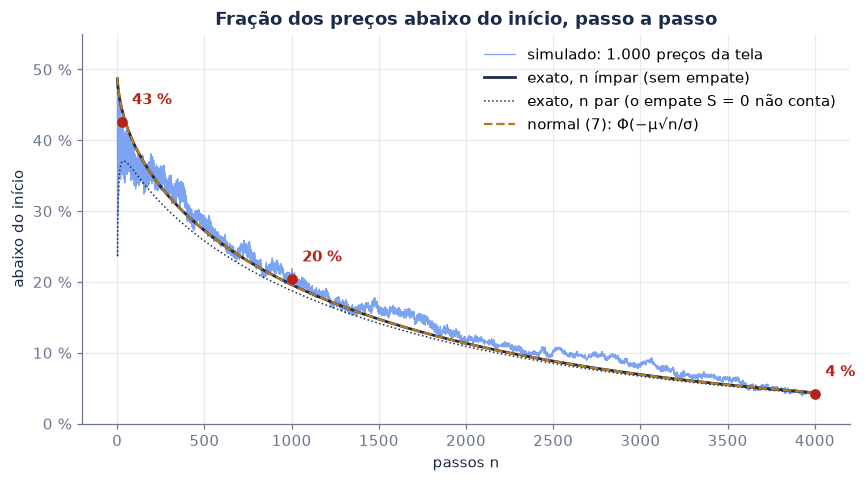

In [8]:
NMAX = 4000
dist = np.zeros(2 * NMAX + 1); dist[NMAX] = 1.0          # posição −4000..4000, começa em 0
exata = np.empty(NMAX)
for k in range(NMAX):
    novo = np.zeros_like(dist)
    novo[1:] += p * dist[:-1]; novo[:-1] += (1 - p) * dist[1:]
    dist = novo
    exata[k] = dist[:NMAX].sum()                         # P(S_n < 0), n = k + 1
normal = np.array([Phi(-deriva * math.sqrt(m) / sigma) for m in range(1, NMAX + 1)])                     # (7)
normal_cc = np.array([Phi((-(m % 2 == 0) - deriva * m) / (sigma * math.sqrt(m))) for m in range(1, NMAX + 1)])  # com correção de continuidade

marcas = [25, 100, 1000, 1368, 4000]
tab = pd.DataFrame([{"passos n": m, "simulado (1.000 preços)": abaixo[m - 1], "erro-padrão de Monte Carlo": math.sqrt(abaixo[m - 1] * (1 - abaixo[m - 1]) / 1000),
                     "exato (binomial)": exata[m - 1], "normal (7)": normal[m - 1], "normal com correção": normal_cc[m - 1]} for m in marcas])
display(tab.style.format({c: fp() for c in tab.columns[1:]} | {"passos n": "{:,.0f}"}, **fmt).hide(axis="index"))
empate = binom_cauda(500, 1000, p) - binom_cauda(501, 1000, p)
print(f"empate em n = 1.000 (preço exatamente no início, não conta como abaixo): P(S = 0) = {pct(empate, 2)}")
print(f"P(S_n < 0) cai abaixo de 5 % pela primeira vez em n = {int(np.argmax(exata < 0.05)) + 1:,} (exata)".replace(",", "."))
for m in (1000, 4000):
    print(f"cota de Chernoff (1 − μ²)^(n/2) em n = {m:,}: {pct((1 - deriva ** 2) ** (m / 2))} (exato: {pct(exata[m - 1])})".replace(",", ".", 1))
assert [round(100 * exata[m - 1]) for m in (25, 1000, 4000)] == [45, 19, 4]
dist_ep = [abs(abaixo[m - 1] - exata[m - 1]) / math.sqrt(exata[m - 1] * (1 - exata[m - 1]) / 1000) for m in marcas]
print("distância simulado × exato, em erros-padrão de Monte Carlo: " + " · ".join(f"n = {br(m, 0)}: {br(d, 2)}" for m, d in zip(marcas, dist_ep)))
assert max(dist_ep) < 1.4

fig, ax = plt.subplots()
ax.plot(t, abaixo, color=LIGHT, lw=0.8, alpha=0.8, label="simulado: 1.000 preços da tela")
ax.plot(t[0::2], exata[0::2], color=NAVY, lw=1.8, label="exato, n ímpar (sem empate)")
ax.plot(t[1::2], exata[1::2], color=NAVY, lw=1.0, ls=":", label="exato, n par (o empate S = 0 não conta)")
ax.plot(t, normal, color=GOLD, lw=1.5, ls="--", label="normal (7): Φ(−μ√n/σ)")
for m, v in zip((25, 1000, 4000), (43, 20, 4)):
    ax.scatter([m], [abaixo[m - 1]], color=RED, zorder=3); ax.annotate(f"{v} %", (m, abaixo[m - 1]), (m + 60, abaixo[m - 1] + 0.025), color=RED, weight="bold")
ax.set(title="Fração dos preços abaixo do início, passo a passo", xlabel="passos n", ylabel="abaixo do início", ylim=(0, 0.55))
ax.yaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f} %"); ax.legend(frameon=False); plt.show()

**Leitura.** A simulação da tela, a binomial exata e a aproximação normal contam a mesma história, dentro do erro de Monte Carlo de 1.000 preços (1,6 ponto em 25 passos). Os "43 %" do vídeo são 42,6 % simulados contra 44,6 % exatos: diferença de pouco mais de um erro-padrão. Um detalhe de contagem: com $n$ par, o preço pode terminar exatamente no início, e esse empate não conta como "abaixo". Por isso a curva exata tem dois ramos (em 100 passos, a normal sem correção erra por 4 pontos), e a correção de continuidade, trocar 0 por −1 no numerador quando $n$ é par, acerta. No curto prazo, uma moeda com vantagem perde quase tanto quanto ganha.

## 6. A corrida: deriva contra aleatoriedade — eq. (8)

A deriva acumulada é $n\mu$; a aleatoriedade típica é $\sigma\sqrt{n}$. Elas se igualam quando $n\mu = \sigma\sqrt{n}$:

$$
n^{*} = \left(\frac{\sigma}{\mu}\right)^{2}, \qquad n_z = \left(\frac{z\,\sigma}{\mu}\right)^{2} \tag{8}
$$

Na moeda do cassino, $n^* = (1368/1369)\cdot 37^2 = 1.368$ **exatamente**. Depois disso, a deriva supera um desvio-padrão da aleatoriedade e, pela eq. (7), só $\Phi(-1) \approx 16\,\%$ dos preços estão abaixo do início.

A versão estatística é $n_z$: quantos passos para a deriva superar $z$ desvios. Com $z = 1{,}645$, a vantagem aparece com 95 % de confiança (só 5 % abaixo do início): **3.701 passos**. É por isso que, nos 4.000 passos da tela, sobram 4 % abaixo. A mesma conta diz quantos lances observar para **provar** que uma moeda é viciada: a frequência de caras $\hat p$ tem erro-padrão $\sigma/(2\sqrt{n})$, e o teste rejeita a moeda justa quando $2\hat p - 1 > z\sigma/\sqrt{n}$, a eq. (8) de novo.

n* = 1.368,00 · n(z = 1,645) = 3.701 · n(z = 1,96) = 5.255
em n*: abaixo do início pela normal = 15,9 %, exato = 15,2 %
o relógio do passeio, n/n*: 25 passos = 0,018 n* · 1.000 passos = 0,731 n* · 4.000 passos = 2,924 n*
em 1.000 passos: deriva +$27,0 contra aleatoriedade ±$31,6 → a moeda justa da tela (+$28) não se distingue da do cassino


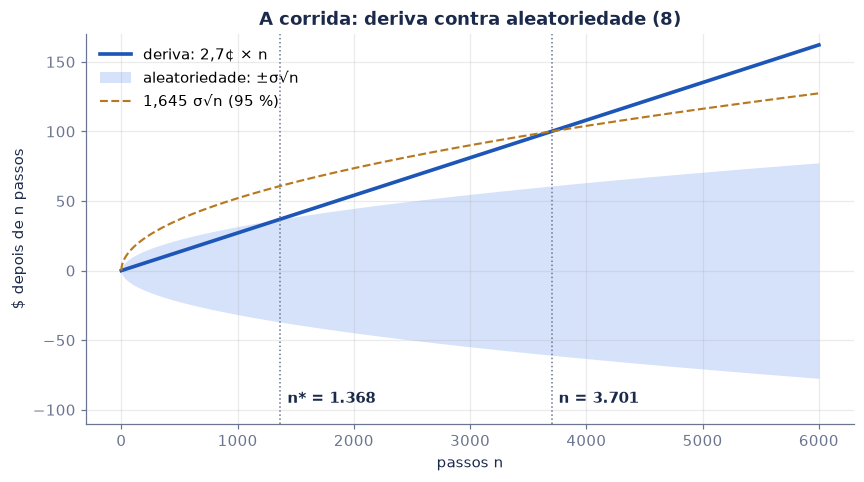

In [9]:
n_star = (sigma / deriva) ** 2
n95, n975 = (Z95 * sigma / deriva) ** 2, (Z975 * sigma / deriva) ** 2
print(f"n* = {br(n_star, 2)} · n(z = 1,645) = {br(n95, 0)} · n(z = 1,96) = {br(n975, 0)}")
print(f"em n*: abaixo do início pela normal = {pct(Phi(-1))}, exato = {pct(exata[1367])}")
print("o relógio do passeio, n/n*: " + " · ".join(f"{br(m, 0)} passos = {br(m / n_star, 3)} n*" for m in (25, 1000, 4000)))
print(f"em 1.000 passos: deriva +${br(1000 * deriva, 1)} contra aleatoriedade ±${br(sigma * math.sqrt(1000), 1)} → a moeda justa da tela (+$28) não se distingue da do cassino")
assert round(n_star) == 1368 and round(n95) == 3701 and round(n975) == 5255

fig, ax = plt.subplots()
nn = np.arange(0, 6001)
ax.plot(nn, deriva * nn, color=BLUE, lw=2.4, label="deriva: 2,7¢ × n")
ax.fill_between(nn, -sigma * np.sqrt(nn), sigma * np.sqrt(nn), color=LIGHT, alpha=0.25, lw=0, label="aleatoriedade: ±σ√n")
ax.plot(nn, Z95 * sigma * np.sqrt(nn), color=GOLD, lw=1.4, ls="--", label="1,645 σ√n (95 %)")
for x, txt in [(n_star, "n* = 1.368"), (n95, "n = 3.701")]:
    ax.axvline(x, color=GREY, ls=":", lw=1); ax.text(x + 60, -95, txt, color=NAVY, weight="bold")
ax.set(title="A corrida: deriva contra aleatoriedade (8)", xlabel="passos n", ylabel="$ depois de n passos", ylim=(-110, 170))
ax.legend(frameon=False, loc="upper left"); plt.show()

## 7. A ruína do jogador — eq. (9)

O passeio com vantagem tem uma versão clássica: o **apostador** contra o **cassino**. Ele começa com $a$ fichas, aposta 1 ficha por rodada no vermelho da roleta europeia (ganha com $p = 18/37$) e para quando chega a $N$ fichas ou quebra. A probabilidade de chegar a $N$ antes de zero (Feller, 1968, cap. XIV), com $r = (1-p)/p$:

$$
\Pr(\text{chegar a } N \text{ antes de } 0 \mid a) = \frac{1 - r^{a}}{1 - r^{N}} \qquad (p \ne \tfrac12;\ \text{com } p = \tfrac12,\ a/N) \tag{9}
$$

Exemplo: você tem **R\$ 100** e quer dobrar para R\$ 200 no vermelho. Muda alguma coisa apostar tudo de uma vez ou de pouco em pouco?

In [10]:
def chega_N(q, a, N):                                    # (9)
    if q == 0.5:
        return a / N
    r = (1 - q) / q
    return (1 - r ** a) / (1 - r ** N)

def simula_ruina(q, a, N, n_sim, rng):
    pos = np.full(n_sim, a); ativo = np.ones(n_sim, bool); passos = np.zeros(n_sim, int)
    while ativo.any():
        idx = np.flatnonzero(ativo)
        pos[idx] += np.where(rng.random(len(idx)) < q, 1, -1); passos[idx] += 1
        ativo[idx] = (pos[idx] > 0) & (pos[idx] < N)
    return (pos >= N).mean(), passos.mean()

rng_r = np.random.default_rng(37)
linhas = []
for aposta in (100, 50, 20, 10, 5, 1):
    a, N = 100 // aposta, 200 // aposta
    sim, dur = simula_ruina(18 / 37, a, N, 20_000, rng_r)
    linhas.append({"aposta por rodada": f"R$ {aposta}", "fichas a → meta N": f"{a} → {N}", "chega a R$ 200 (9)": chega_N(18 / 37, a, N),
                   "simulação (20.000)": sim, "rodadas em média": dur, "rodadas pela fórmula": a / (1 - 2 * 18 / 37) - N / (1 - 2 * 18 / 37) * chega_N(18 / 37, a, N),
                   "moeda justa": chega_N(0.5, a, N)})
ruina = pd.DataFrame(linhas)
display(ruina.style.format({"chega a R$ 200 (9)": fp(2), "simulação (20.000)": fp(2), "rodadas em média": "{:,.0f}", "rodadas pela fórmula": "{:,.0f}", "moeda justa": fp(0)}, **fmt).hide(axis="index"))
assert round(100 * chega_N(18 / 37, 1, 2), 1) == 48.6 and round(100 * chega_N(18 / 37, 10, 20), 1) == 36.8 and round(100 * chega_N(18 / 37, 100, 200), 2) == 0.45
assert all(abs(l["chega a R$ 200 (9)"] - l["simulação (20.000)"]) < 0.012 for l in linhas)

aposta por rodada,fichas a → meta N,chega a R$ 200 (9),simulação (20.000),rodadas em média,rodadas pela fórmula,moeda justa
R$ 100,1 → 2,"48,65 %","48,49 %",1,1,50 %
R$ 50,2 → 4,"47,30 %","47,37 %",4,4,50 %
R$ 20,5 → 10,"43,28 %","43,01 %",25,25,50 %
R$ 10,10 → 20,"36,80 %","36,99 %",98,98,50 %
R$ 5,20 → 40,"25,33 %","25,35 %",365,365,50 %
R$ 1,100 → 200,"0,45 %","0,48 %",3.639,3.667,50 %


**Leitura.** Numa moeda justa, tanto faz: 50 % em qualquer tamanho de aposta. Contra a casa, **apostar pouco é o pior**: uma aposta de R\$ 100 dobra a banca em 48,6 % das vezes; cem apostas de R\$ 1, em 0,45 %. É a corrida da seção 6 vista do outro lado: quanto mais rodadas, mais a deriva (que é do cassino) vence o ruído (que era a única chance do apostador). O cassino gosta de jogadores que jogam muito, e não de jogadores que apostam alto.

## 8. Dado real: o Ibovespa é um passeio aleatório? — eqs. (10) e (11)

A pergunta do vídeo, "um gráfico de ações é mesmo só uma sequência de lances de moeda?", tem um teste clássico. Se o log do preço é um passeio aleatório, os retornos não têm memória, e a variância de um retorno de $q$ dias é $q$ vezes a variância de um dia (eq. (3) com $\mu$ irrelevante). **Lo & MacKinlay (1988)** compararam as duas:

$$
VR(q) = \frac{\mathrm{Var}\big(r_t + r_{t-1} + \cdots + r_{t-q+1}\big)}{q\,\mathrm{Var}(r_t)} = 1 + 2\sum_{k=1}^{q-1}\Big(1 - \frac{k}{q}\Big)\rho_k \tag{10}
$$

No passeio aleatório, $VR(q) = 1$. Autocorrelação positiva ($\rho_k > 0$, tendência) dá $VR > 1$; negativa (reversão) dá $VR < 1$. O ponto do artigo é a estatística de teste **robusta à heteroscedasticidade**: retornos de bolsa têm fases calmas e agitadas, e o teste ingênuo erra por isso. Com $nq$ retornos, média $\hat\mu$ e

$$
z^{*}(q) = \frac{\sqrt{nq}\,\big(\widehat{VR}(q) - 1\big)}{\sqrt{\hat\theta(q)}},\qquad
\hat\theta(q) = \sum_{k=1}^{q-1}\Big[\frac{2(q-k)}{q}\Big]^2\hat\delta(k),\qquad
\hat\delta(k) = \frac{nq\sum_{j=k+1}^{nq}(r_j-\hat\mu)^2(r_{j-k}-\hat\mu)^2}{\Big[\sum_{j=1}^{nq}(r_j-\hat\mu)^2\Big]^2} \tag{11}
$$

$z^*$ é aproximadamente normal padrão sob o passeio aleatório, mesmo com variância que muda no tempo. A versão ingênua troca $\hat\theta(q)$ por $2(2q-1)(q-1)/(3q)$. Usamos as variâncias com sobreposição e as correções de viés do artigo. Como conferência extra, o erro-padrão de $VR(q)$ também sai de um **bootstrap em blocos** (Künsch, 1989): dias não são independentes, então reamostramos blocos de dias consecutivos.

Por que um preço deveria se parecer com lances de moeda? Bachelier (1900) já modelava a bolsa de Paris assim, e Samuelson (1965) deu o argumento econômico: se o preço de hoje já incorpora tudo o que se sabe, a variação de amanhã depende só da notícia de amanhã, que ninguém prevê. O que sobra de previsível é a deriva, o retorno que o investidor exige para carregar o risco. Fama (1965, 1970) transformou isso na hipótese dos mercados eficientes e em testes como este.

Os dados: o fechamento diário do Ibovespa (`^BVSP`, Yahoo Finance) de 02/01/1995 a 16/10/2026. O Ibovespa já é um índice de retorno total (reinveste os proventos).

In [11]:
ibov = pd.read_csv("dados/ibovespa.csv", parse_dates=["data"]).set_index("data")["ibov"]
cdi = pd.read_csv("dados/cdi_diario.csv", parse_dates=["data"]).set_index("data")["cdi_pct_ad"]
print(f"Ibovespa: {len(ibov):,} fechamentos de {ibov.index[0]:%d/%m/%Y} a {ibov.index[-1]:%d/%m/%Y}; datas repetidas: {ibov.index.duplicated().sum()}".replace(",", "."))
r_bruto = np.log(ibov).diff().dropna()
parados = r_bruto[r_bruto == 0].index
print(f"{len(parados)} dias com retorno exatamente zero (preço repetido em feriado ou dia sem pregão), removidos: " + ", ".join(f"{d:%d/%m/%Y}" for d in parados[:5]) + ", …")
ibov = ibov.drop(parados)
r = np.log(ibov).diff().dropna()
extremos = pd.concat([r.nsmallest(4), r.nlargest(4)]).sort_index()
print("os 8 dias mais extremos (conferidos com a história: México em 1995, Ásia em 1997, Rússia em 1998, a desvalorização do real em 1999, a crise de 2008, a covid em 2020):")
print("  " + " · ".join(f"{d:%d/%m/%Y} {'+' if v > 0 else '−'}{br(100 * abs(math.expm1(v)), 1)} %" for d, v in extremos.items()))
assert ibov.index.is_monotonic_increasing and not ibov.index.duplicated().any() and len(parados) == 13
assert round(100 * math.expm1(r.max()), 1) == 33.4 and r.idxmax() == pd.Timestamp("1999-01-15")

Ibovespa: 7.875 fechamentos de 02/01/1995 a 16/10/2026; datas repetidas: 0
13 dias com retorno exatamente zero (preço repetido em feriado ou dia sem pregão), removidos: 28/06/1995, 15/11/1995, 27/06/1996, 07/01/1997, 07/02/1997, …
os 8 dias mais extremos (conferidos com a história: México em 1995, Ásia em 1997, Rússia em 1998, a desvalorização do real em 1999, a crise de 2008, a covid em 2020):
  10/03/1995 +25,6 % · 27/10/1997 −15,0 % · 10/09/1998 −15,8 % · 15/09/1998 +18,7 % · 15/01/1999 +33,4 % · 13/10/2008 +14,7 % · 12/03/2020 −14,8 % · 16/03/2020 −13,9 %


In [12]:
def razao_variancias(x, q):
    # VR(q) com sobreposição e correção de viés (Lo e MacKinlay, 1988), z homocedástico e z* robusto (11)
    x = np.asarray(x, float); nq = len(x); mu = x.mean(); e = x - mu
    var_a = (e ** 2).sum() / (nq - 1)
    cs = np.r_[0.0, np.cumsum(x)]
    m = q * (nq - q + 1) * (1 - q / nq)
    var_c = ((cs[q:] - cs[:-q] - q * mu) ** 2).sum() / m
    vr = var_c / var_a
    e2 = e ** 2; den = e2.sum() ** 2
    theta = sum((2 * (q - k) / q) ** 2 * nq * (e2[k:] * e2[:-k]).sum() / den for k in range(1, q))
    z = math.sqrt(nq) * (vr - 1) / math.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q))
    return vr, z, math.sqrt(nq) * (vr - 1) / math.sqrt(theta)

def so_vr(x, qs):
    x = np.asarray(x, float); nq = len(x); mu = x.mean(); cs = np.r_[0.0, np.cumsum(x)]
    var_a = ((x - mu) ** 2).sum() / (nq - 1)
    return np.array([((cs[q:] - cs[:-q] - q * mu) ** 2).sum() / (q * (nq - q + 1) * (1 - q / nq)) / var_a for q in qs])

def bootstrap_blocos(x, estat, L, B=2000, seed=7):
    # bootstrap de blocos móveis (Künsch, 1989): blocos de L observações consecutivas, colados até o tamanho da amostra
    x = np.asarray(x, float); n = len(x); g = np.random.default_rng(seed); nb = -(-n // L)
    return np.array([estat(x[(g.integers(0, n - L + 1, nb)[:, None] + np.arange(L)).ravel()[:n]]) for _ in range(B)])

semanal = np.log(ibov.resample("W-WED").last()).diff().dropna()   # quarta a quarta, como no artigo
QS = (2, 4, 8, 16)
linhas = []
for nome, x, L in [("diário", r, 20), ("semanal", semanal, 12)]:
    boot = bootstrap_blocos(x, lambda s: so_vr(s, QS), L)
    for j, q in enumerate(QS):
        vr, z, zs = razao_variancias(x, q)
        lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
        linhas.append({"retornos": nome, "n": len(x), "q": q, "VR(q) (10)": vr, "z ingênuo": z, "z* robusto (11)": zs,
                       "bootstrap: IC 95 %": f"{br(lo, 3)} a {br(hi, 3)}", "rejeita a 5 %? (z*)": "sim" if abs(zs) > Z975 else "não"})
vr_tab = pd.DataFrame(linhas)
display(vr_tab.style.format({"VR(q) (10)": "{:.3f}", "z ingênuo": "{:+.2f}", "z* robusto (11)": "{:+.2f}", "n": "{:,.0f}"}, **fmt).hide(axis="index")
        .set_caption("Razão de variâncias do Ibovespa, 1995–2026 (log-retornos; diário: blocos de 20 dias; semanal: blocos de 12 semanas)"))
print(f"{len(r):,} retornos diários e {len(semanal):,} semanais".replace(",", "."))
for q in QS:
    print(f"q = {q:2d}: variância assintótica ingênua 2(2q−1)(q−1)/(3q) = {br(2 * (2 * q - 1) * (q - 1) / (3 * q), 3)}; robusta θ̂(q) diária = {br((razao_variancias(r, q)[1] / razao_variancias(r, q)[2]) ** 2 * 2 * (2 * q - 1) * (q - 1) / (3 * q), 3)}")
assert (vr_tab["z* robusto (11)"].abs() < Z975).all()                       # nenhum z* rejeita a 5 %
assert (vr_tab["z ingênuo"].abs() > Z975).sum() == 2                        # o ingênuo rejeita duas vezes

retornos,n,q,VR(q) (10),z ingênuo,z* robusto (11),bootstrap: IC 95 %,rejeita a 5 %? (z*)
diário,7.861,2,"1,005","+0,45","+0,19","0,959 a 1,038",não
diário,7.861,4,"0,981","-0,90","-0,38","0,933 a 1,031",não
diário,7.861,8,"0,878","-3,64","-1,61","0,829 a 0,994",não
diário,7.861,16,"0,906","-1,89","-0,89","0,787 a 1,048",não
semanal,1.659,2,"0,904","-3,92","-1,70","0,836 a 1,018",não
semanal,1.659,4,"0,948","-1,14","-0,53","0,838 a 1,102",não
semanal,1.659,8,"0,988","-0,16","-0,08","0,827 a 1,202",não
semanal,1.659,16,"0,908","-0,85","-0,49","0,758 a 1,279",não


7.861 retornos diários e 1.659 semanais
q =  2: variância assintótica ingênua 2(2q−1)(q−1)/(3q) = 1,000; robusta θ̂(q) diária = 5,350
q =  4: variância assintótica ingênua 2(2q−1)(q−1)/(3q) = 3,500; robusta θ̂(q) diária = 19,253
q =  8: variância assintótica ingênua 2(2q−1)(q−1)/(3q) = 8,750; robusta θ̂(q) diária = 44,808
q = 16: variância assintótica ingênua 2(2q−1)(q−1)/(3q) = 19,375; robusta θ̂(q) diária = 86,769


In [13]:
periodos = [("1995", "2002"), ("2003", "2010"), ("2011", "2018"), ("2019", "2026")]
linhas = []
for a, b in periodos:
    for nome, x in [("diário", r[a:b]), ("semanal", semanal[a:b])]:
        lin = {"período": f"{a}–{b}", "retornos": nome, "ρ₁": x.autocorr(1)}
        for q in (2, 8):
            vr, _, zs = razao_variancias(x, q)
            lin[f"VR({q})"], lin[f"z*({q})"] = vr, zs
        linhas.append(lin)
sub = pd.DataFrame(linhas)
display(sub.style.format({"ρ₁": "{:+.3f}", "VR(2)": "{:.3f}", "VR(8)": "{:.3f}", "z*(2)": "{:+.2f}", "z*(8)": "{:+.2f}"}, **fmt).hide(axis="index").set_caption("Por subperíodo"))

x = r["2019":"2026"]
sem_covid = x.drop(x["2020-02-15":"2020-06-30"].index)
b_rho = bootstrap_blocos(r.values, lambda s: np.corrcoef(s[1:], s[:-1])[0, 1], 20)
print(f"ρ₁ diário 1995–2026 = {br(r.autocorr(1), 3)}, IC 95 % por bootstrap em blocos: {br(np.percentile(b_rho, 2.5), 3)} a {br(np.percentile(b_rho, 97.5), 3)}")
print(f"ρ₁ diário 2019–2026 = {br(x.autocorr(1), 3)}; sem fev–jun de 2020 = {br(sem_covid.autocorr(1), 3)}: quatro meses de covid fazem quase toda a autocorrelação")
abs_ac = [r.abs().autocorr(k) for k in (1, 5, 20, 60)]
print("autocorrelação do retorno ABSOLUTO |r| (o tamanho do movimento) em 1, 5, 20 e 60 dias: " + " · ".join(br(v, 2) for v in abs_ac))
assert round(x.autocorr(1), 2) == -0.14 and abs(sem_covid.autocorr(1)) < 0.05 and min(abs_ac) > 0.09

período,retornos,ρ₁,VR(2),z*(2),VR(8),z*(8)
1995–2002,diário,"+0,055","1,056","+1,25","0,883","-0,92"
1995–2002,semanal,"-0,162","0,837","-1,68","0,922","-0,32"
2003–2010,diário,"-0,006","0,995","-0,16","0,810","-1,70"
2003–2010,semanal,"-0,059","0,945","-1,00","1,079","+0,44"
2011–2018,diário,"-0,010","0,990","-0,38","0,924","-0,98"
2011–2018,semanal,"-0,040","0,963","-0,67","1,074","+0,48"
2019–2026,diário,"-0,137","0,863","-1,57","0,943","-0,23"
2019–2026,semanal,"+0,038","1,038","+0,24","1,100","+0,29"


ρ₁ diário 1995–2026 = 0,005, IC 95 % por bootstrap em blocos: −0,041 a 0,038
ρ₁ diário 2019–2026 = −0,137; sem fev–jun de 2020 = −0,036: quatro meses de covid fazem quase toda a autocorrelação
autocorrelação do retorno ABSOLUTO |r| (o tamanho do movimento) em 1, 5, 20 e 60 dias: 0,30 · 0,27 · 0,19 · 0,10


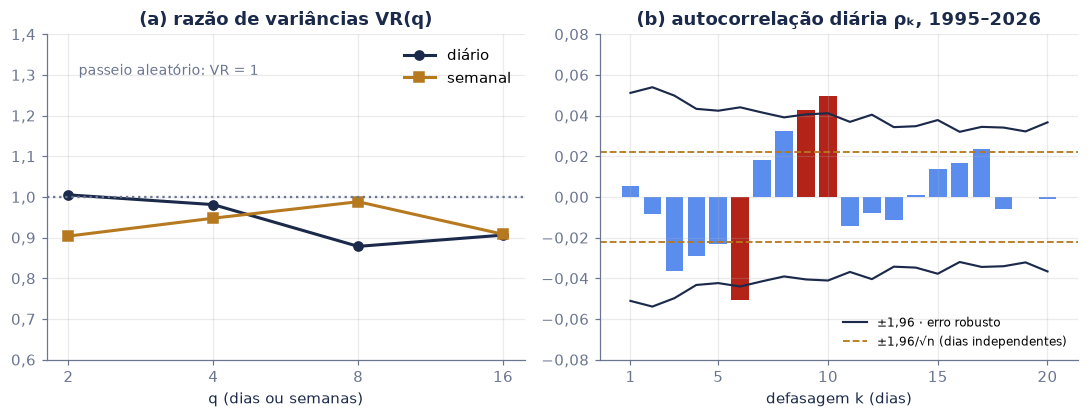

defasagens fora da banda robusta: [6, 9, 10] · fora da banda ingênua: [3, 4, 5, 6, 8, 9, 10, 17]


In [14]:
K = 20
nq = len(r); e = (r - r.mean()).values; e2 = e ** 2
rho = np.array([r.autocorr(k) for k in range(1, K + 1)])
banda_iid = Z975 / math.sqrt(nq)
banda_rob = np.array([Z975 * math.sqrt(nq * (e2[k:] * e2[:-k]).sum() / (e2.sum() ** 2) / nq) for k in range(1, K + 1)])   # √δ(k)/√n
fig, axs = plt.subplots(1, 2, figsize=(10, 3.9))
ax = axs[0]
for nome, c, mk in [("diário", NAVY, "o"), ("semanal", GOLD, "s")]:
    d = vr_tab[vr_tab["retornos"] == nome]
    ax.plot(d["q"], d["VR(q) (10)"], mk + "-", color=c, lw=2, label=nome)
ax.axhline(1, color=GREY, ls=":"); ax.set_xscale("log", base=2); ax.set_xticks(QS, [str(q) for q in QS])
ax.set(title="(a) razão de variâncias VR(q)", xlabel="q (dias ou semanas)", ylim=(0.6, 1.4)); ax.legend(frameon=False)
ax.yaxis.set_major_formatter(lambda v, _: br(v, 1))
ax.text(2.1, 1.3, "passeio aleatório: VR = 1", color=GREY, fontsize=9)
ax = axs[1]
ks = np.arange(1, K + 1)
ax.bar(ks, rho, color=[RED if abs(v) > b else LIGHT for v, b in zip(rho, banda_rob)])
ax.plot(ks, banda_rob, color=NAVY, lw=1.4, label="±1,96 · erro robusto"); ax.plot(ks, -banda_rob, color=NAVY, lw=1.4)
ax.axhline(banda_iid, color=GOLD, ls="--", lw=1.2, label="±1,96/√n (dias independentes)"); ax.axhline(-banda_iid, color=GOLD, ls="--", lw=1.2)
ax.set(title="(b) autocorrelação diária ρₖ, 1995–2026", xlabel="defasagem k (dias)", ylim=(-0.08, 0.08), xticks=[1, 5, 10, 15, 20]); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.yaxis.set_major_formatter(lambda v, _: br(v, 2))
fig.tight_layout(); plt.show()
print("defasagens fora da banda robusta:", [int(k) for k, v, b in zip(ks, rho, banda_rob) if abs(v) > b], "· fora da banda ingênua:", [int(k) for k, v in zip(ks, rho) if abs(v) > banda_iid])

**Leitura.** Com o teste robusto, **o Ibovespa não rejeita o passeio aleatório** a 5 % em nenhum horizonte, diário ou semanal, de 1995 a 2026. As razões de variâncias ficam um pouco abaixo de 1 (uma pitada de reversão), mas dentro do ruído. Três lições:

1. **O teste ingênuo erraria.** Sem a correção de heteroscedasticidade, $VR(8)$ diário e $VR(2)$ semanal "rejeitariam" o passeio aleatório. A culpa é das fases agitadas (1998–1999, 2008, 2020): poucos dias enormes inflam a estatística. Foi para isso que Lo & MacKinlay construíram o $z^*$. No gráfico (b), a banda ingênua deixa 8 das 20 autocorrelações de fora; a robusta, 3 (as defasagens 6, 9 e 10, isoladas e de sinais trocados). Com 20 defasagens testadas a 5 %, uma ou duas passariam por acaso; três é pouco mais que isso, e sem padrão para operar.
2. **Um evento pode fazer o resultado.** A autocorrelação diária de −0,14 em 2019–2026 vem quase toda de fevereiro a junho de 2020; sem esses meses, ela é −0,04.
3. **Sem memória no sinal, com memória no tamanho.** O retorno não se autocorrelaciona, mas o retorno *absoluto* sim, por meses. É o "fases calmas e agitadas" do vídeo, e o passeio da moeda não tem isso.

Lo & MacKinlay rejeitaram o passeio aleatório para índices semanais americanos de 1962 a 1985, com autocorrelação **positiva**, sobretudo no índice de pesos iguais, puxado pelas ações pequenas. No Ibovespa de 1995 a 2026, um índice de ações grandes e líquidas, o resultado é o oposto: não há tendência de curto prazo para explorar. Não rejeitar não prova que o preço é um passeio aleatório; diz só que a memória linear dos retornos, se existe, é pequena demais para este teste ver.

## 9. Para o investidor: Ibovespa contra o CDI como deriva + ruído — eq. (12)

O fecho do vídeo é o modelo mais simples de um preço: **variação = deriva + passo aleatório**, e para ações parte da deriva é o prêmio de risco. Para o investidor brasileiro, o prêmio que importa é sobre o **CDI**, o que o dinheiro rende parado. Seja $X_t$ o log-retorno do Ibovespa menos o log-retorno do CDI no mesmo período. Se $X_t$ é um passeio com deriva $\mu$ e volatilidade $\sigma$ por ano, a chance de o Ibovespa terminar **abaixo do CDI** depois de $T$ anos é a eq. (7) em tempo contínuo:

$$
\Pr\big(\text{Ibovespa abaixo do CDI em } T \text{ anos}\big) \approx \Phi\!\left(-\frac{\mu\sqrt{T}}{\sigma}\right) \tag{12}
$$

O CDI diário (série 12 do SGS) é acumulado no seu próprio calendário e lido em cada data de pregão do Ibovespa. Antes do resultado, a medida: os dois têm calendários diferentes (feriados municipais de São Paulo, dias sem CDI), e o índice acumulado resolve isso sem perder nenhum dia de juros.

In [15]:
fator_cdi = (1 + cdi / 100).cumprod()
fator_cdi = fator_cdi.reindex(fator_cdi.index.union(ibov.index)).ffill().reindex(ibov.index)   # CDI acumulado lido em cada pregão
excesso = np.log(ibov) - np.log(fator_cdi)
excesso = excesso - excesso.iloc[0]
x_d = excesso.diff().dropna()
T = (ibov.index[-1] - ibov.index[0]).days / 365.25
por_ano = len(x_d) / T
mu_x = excesso.iloc[-1] / T                                   # deriva em log, por ano
sig_x = x_d.std(ddof=1) * math.sqrt(por_ano)
ibov_aa = math.exp(math.log(ibov.iloc[-1] / ibov.iloc[0]) / T) - 1
cdi_aa = math.exp(math.log(fator_cdi.iloc[-1] / fator_cdi.iloc[0]) / T) - 1
boot_mu = bootstrap_blocos(x_d.values, lambda s: s.mean() * por_ano, 20)
print(f"{br(T, 2)} anos, {br(len(x_d), 0)} pregões ({br(por_ano, 1)} por ano)")
cdi_95 = fator_cdi["1995"].iloc[-1] / fator_cdi.iloc[0] - 1
print(f"CDI acumulado em 1995: {pct(cdi_95)} no ano")
print(f"R$ 10.000 em 02/01/1995: no Ibovespa, {brl(1e4 * ibov.iloc[-1] / ibov.iloc[0])}; no CDI, {brl(1e4 * fator_cdi.iloc[-1] / fator_cdi.iloc[0])} (antes de imposto e custos)")
print(f"ao ano: Ibovespa {pct(ibov_aa)}, CDI {pct(cdi_aa)}")
print(f"deriva do excesso (log) μ = {pct(mu_x, 2)} ao ano · volatilidade σ = {pct(sig_x)} ao ano")
print(f"erro-padrão de μ: σ/√T = {pct(sig_x / math.sqrt(T))}; bootstrap em blocos de 20 dias = {pct(boot_mu.std())} · IC 95 %: {pct(np.percentile(boot_mu, 2.5))} a {pct(np.percentile(boot_mu, 97.5))}")
print(f"média aritmética do excesso anual ≈ μ + σ²/2 = {pct(mu_x + sig_x ** 2 / 2, 2)}: o 'ano médio' ganhou do CDI; o investidor de 31 anos, não")
assert mu_x < 0 and round(100 * mu_x, 1) == -1.8 and round(100 * sig_x) == 31
assert np.percentile(boot_mu, 2.5) < 0 < np.percentile(boot_mu, 97.5)

31,79 anos, 7.861 pregões (247,3 por ano)
CDI acumulado em 1995: 52,6 % no ano
R$ 10.000 em 02/01/1995: no Ibovespa, R$ 477.633; no CDI, R$ 843.621 (antes de imposto e custos)
ao ano: Ibovespa 12,9 %, CDI 15,0 %
deriva do excesso (log) μ = −1,79 % ao ano · volatilidade σ = 30,8 % ao ano
erro-padrão de μ: σ/√T = 5,5 %; bootstrap em blocos de 20 dias = 5,3 % · IC 95 %: −11,8 % a 8,5 %
média aritmética do excesso anual ≈ μ + σ²/2 = 2,96 %: o 'ano médio' ganhou do CDI; o investidor de 31 anos, não


In [16]:
linhas = []
for a, b in periodos:
    s = excesso[a:b]; TT = (s.index[-1] - s.index[0]).days / 365.25
    linhas.append({"período": f"{a}–{b}", "excesso sobre o CDI (log, ao ano)": (s.iloc[-1] - s.iloc[0]) / TT, "volatilidade": s.diff().std() * math.sqrt(por_ano)})
display(pd.DataFrame(linhas).style.format({"excesso sobre o CDI (log, ao ano)": lambda v: f"{100 * v:+.1f} %", "volatilidade": fp()}, **fmt).hide(axis="index"))

anual = excesso.resample("YE").last().diff()
anual.iloc[0] = excesso.resample("YE").last().iloc[0]
anos_cheios = anual[:"2025"]
print(f"anos-calendário 1995–2025: o Ibovespa perdeu do CDI em {(anos_cheios < 0).sum()} de {len(anos_cheios)}")

h_list = [1, 2, 3, 5, 10]
linhas = []
for h in h_list:
    janelas = excesso.diff(int(round(h * por_ano))).dropna()
    linhas.append({"horizonte (anos)": h, "modelo (12), μ = " + pct(mu_x, 1): Phi(-mu_x * math.sqrt(h) / sig_x), "histórico: janelas móveis": (janelas < 0).mean(),
                   "janelas": len(janelas), "independentes": int(T // h), "se o prêmio fosse +5 % (12)": Phi(-0.05 * math.sqrt(h) / sig_x)})
hor = pd.DataFrame(linhas)
display(hor.style.format({c: fp() for c in hor.columns if c not in ("horizonte (anos)", "janelas", "independentes")} | {"janelas": "{:,.0f}"}, **fmt).hide(axis="index")
        .set_caption("Chance de o Ibovespa ficar abaixo do CDI depois de T anos"))
n_star_anos = (sig_x / mu_x) ** 2
print(f"anos para a deriva vencer o ruído, n* = (σ/μ)² (8): {br(n_star_anos, 0)} anos com μ = {pct(mu_x, 2)} (e a deriva é do CDI)")
for prem in (0.03, 0.05):
    print(f"se o prêmio fosse +{pct(prem, 0)}: n* = {br((sig_x / prem) ** 2, 0)} anos; para aparecer com 95 % (z = 1,645): {br((Z95 * sig_x / prem) ** 2, 0)} anos")
assert round(n_star_anos) > 250 and 30 < (sig_x / 0.05) ** 2 < 45

período,"excesso sobre o CDI (log, ao ano)",volatilidade
1995–2002,"-11,1 %","42,6 %"
2003–2010,"+8,8 %","30,4 %"
2011–2018,"-6,9 %","22,9 %"
2019–2026,"+1,3 %","23,2 %"


anos-calendário 1995–2025: o Ibovespa perdeu do CDI em 15 de 31


horizonte (anos),"modelo (12), μ = −1,8 %",histórico: janelas móveis,janelas,independentes,se o prêmio fosse +5 % (12)
1,"52,3 %","49,5 %",7.615,31,"43,6 %"
2,"53,3 %","53,0 %",7.367,15,"40,9 %"
3,"54,0 %","58,0 %",7.120,10,"38,9 %"
5,"55,2 %","59,3 %",6.625,6,"35,8 %"
10,"57,3 %","65,4 %",5.389,3,"30,4 %"


anos para a deriva vencer o ruído, n* = (σ/μ)² (8): 297 anos com μ = −1,79 % (e a deriva é do CDI)
se o prêmio fosse +3 %: n* = 106 anos; para aparecer com 95 % (z = 1,645): 286 anos
se o prêmio fosse +5 %: n* = 38 anos; para aparecer com 95 % (z = 1,645): 103 anos


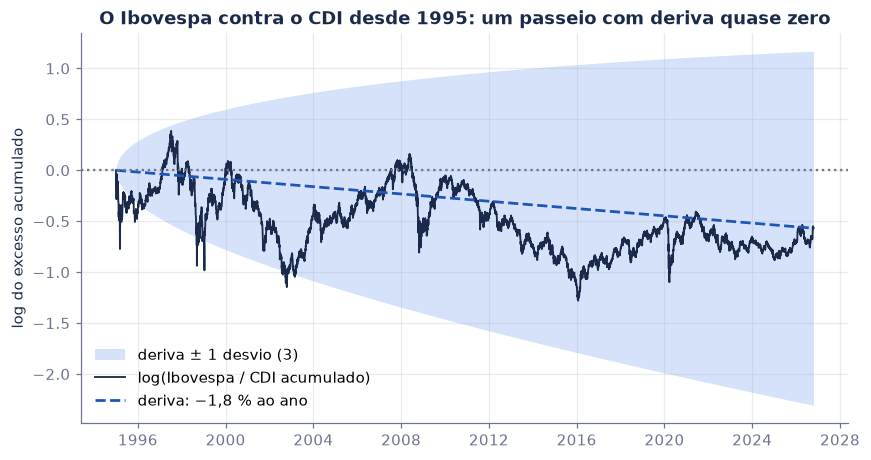

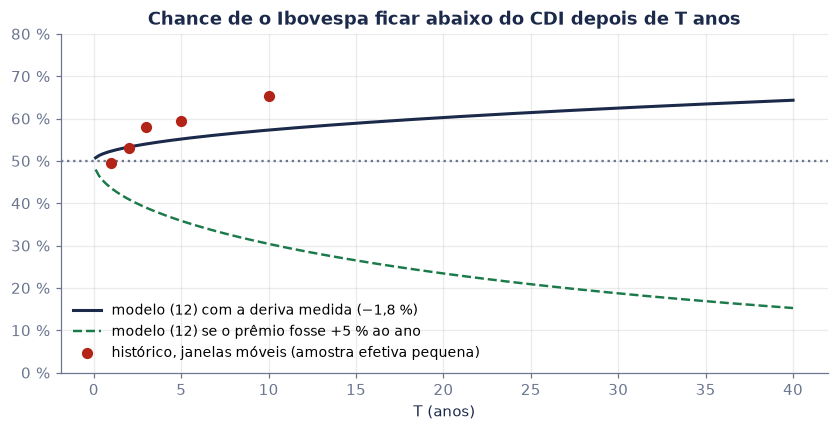

In [17]:
fig, ax = plt.subplots()
anos_t = (excesso.index - excesso.index[0]).days / 365.25
ax.fill_between(excesso.index, mu_x * anos_t - sig_x * np.sqrt(anos_t), mu_x * anos_t + sig_x * np.sqrt(anos_t), color=LIGHT, alpha=0.25, lw=0, label="deriva ± 1 desvio (3)")
ax.plot(excesso.index, excesso, color=NAVY, lw=1.2, label="log(Ibovespa / CDI acumulado)")
ax.plot(excesso.index, mu_x * anos_t, color=BLUE, ls="--", lw=1.8, label=f"deriva: {pct(mu_x, 1)} ao ano")
ax.axhline(0, color=GREY, ls=":")
ax.set(title="O Ibovespa contra o CDI desde 1995: um passeio com deriva quase zero", ylabel="log do excesso acumulado")
ax.legend(frameon=False, loc="lower left"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
hh = np.linspace(0.1, 40, 200)
ax.plot(hh, [Phi(-mu_x * math.sqrt(h) / sig_x) for h in hh], color=NAVY, lw=2, label=f"modelo (12) com a deriva medida ({pct(mu_x, 1)})")
ax.plot(hh, [Phi(-0.05 * math.sqrt(h) / sig_x) for h in hh], color=GREEN, lw=1.6, ls="--", label="modelo (12) se o prêmio fosse +5 % ao ano")
ax.scatter(hor["horizonte (anos)"], hor["histórico: janelas móveis"], color=RED, zorder=3, s=40, label="histórico, janelas móveis (amostra efetiva pequena)")
ax.axhline(0.5, color=GREY, ls=":")
ax.set(title="Chance de o Ibovespa ficar abaixo do CDI depois de T anos", xlabel="T (anos)", ylim=(0, 0.8))
ax.yaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f} %"); ax.legend(frameon=False, fontsize=9, loc="lower left"); plt.show()

**Leitura.** Resultado ruim também vai ao ar: **desde 1995, o Ibovespa rendeu menos que o CDI**, cerca de 1,8 % ao ano a menos, em log; R\$ 10.000 viraram R\$ 478 mil na bolsa e R\$ 844 mil no CDI. Ano a ano, deu empate: a bolsa perdeu em 15 dos 31 anos-calendário. Mas a frase importante é outra: com volatilidade de 31 % ao ano, o erro-padrão da deriva em 31,8 anos é de 5 a 6 pontos, e o intervalo de 95 % do bootstrap vai de −11,8 % a +8,5 % ao ano. **Trinta anos de dados não dizem se a bolsa brasileira paga prêmio sobre o CDI.**

É a eq. (8) com números de verdade. Mesmo que o prêmio fosse de 5 % ao ano (generoso para um país onde o CDI já paga juro real alto), a deriva levaria cerca de 38 anos para passar de um desvio do ruído, e mais de um século para aparecer com 95 % de confiança. Merton (1980) mostrou por que dados diários não ajudam: a precisão da média depende do **tempo** de amostra, não do número de observações.

Duas ressalvas. As janelas móveis se sobrepõem: 31,8 anos têm só 6 janelas independentes de 5 anos e 3 de 10, então os pontos vermelhos são uma amostra efetiva pequena (e as primeiras começam em 1995, quando o CDI rendeu mais de 50 % no ano). E a média aritmética do excesso anual é positiva (+3,0 %): o "ano médio" ganhou do CDI, mas a volatilidade come $\sigma^2/2$ do retorno composto. Preços se movem em porcentagem; o vídeo avisa.

## 10. Mesa de operações: 52 % de acerto é habilidade ou sorte?

Um operador acerta 52 % dos trades, cada um com ganho ou perda de **R\$ 1.000** (alvo e *stop* simétricos). Cada trade é um passo da eq. (1) com $p = 0{,}52$: deriva $\mu$ = R\$ 40 por trade e risco $\sigma$ = R\$ 999,20. Quantos trades até a deriva aparecer? A eq. (8) responde, e o **custo por trade** (corretagem, emolumentos, *spread* e *slippage*) sai direto da deriva: $\mu_{\text{líq}} = \mu - c$.

In [18]:
acerto, risco = 0.52, 1000
mu_t, sig_t = (2 * acerto - 1) * risco, math.sqrt(1 - (2 * acerto - 1) ** 2) * risco      # (1) e (2) em reais
linhas = []
for c in (0, 5, 10, 20, 30):
    mu_l = mu_t - c
    linhas.append({"custo por trade": brl(c), "deriva líquida": brl(mu_l), "n* (8)": (sig_t / mu_l) ** 2, "n para 95 % (8)": (Z95 * sig_t / mu_l) ** 2,
                   "anos a 1 trade por dia": (Z95 * sig_t / mu_l) ** 2 / 252, "P(prejuízo em 1 ano) (7)": Phi(-mu_l * math.sqrt(252) / sig_t)})
custo = pd.DataFrame(linhas)
display(custo.style.format({"n* (8)": "{:,.0f}", "n para 95 % (8)": "{:,.0f}", "anos a 1 trade por dia": "{:.1f}", "P(prejuízo em 1 ano) (7)": fp()}, **fmt).hide(axis="index"))

sorte = []
for n_tr in (252, 1000, 2500):
    sorte.append({"trades": n_tr, "operador sem habilidade (50 %) mostra ≥ 52 %": binom_cauda(math.ceil(0.52 * n_tr - 1e-9), n_tr, 0.5),
                  "operador de 52 % mostra < 50 %": 1 - binom_cauda(math.ceil(0.5 * n_tr), n_tr, 0.52)})
display(pd.DataFrame(sorte).style.format({"trades": "{:,.0f}", "operador sem habilidade (50 %) mostra ≥ 52 %": fp(), "operador de 52 % mostra < 50 %": fp()}, **fmt).hide(axis="index"))
print(f"Sharpe do operador: {br(mu_t / sig_t, 4)} por trade, {br(mu_t / sig_t * math.sqrt(252), 3)} ao ano com 252 trades → anos para 95 %: (1,645 / Sharpe anual)² = {br((Z95 / (mu_t / sig_t * math.sqrt(252))) ** 2, 1)}")
assert round((sig_t / mu_t) ** 2) == 624 and round((Z95 * sig_t / mu_t) ** 2) == 1688

custo por trade,deriva líquida,n* (8),n para 95 % (8),anos a 1 trade por dia,P(prejuízo em 1 ano) (7)
R$ 0,R$ 40,624,1.688,"6,7","26,3 %"
R$ 5,R$ 35,815,2.205,"8,8","28,9 %"
R$ 10,R$ 30,1.109,3.001,"11,9","31,7 %"
R$ 20,R$ 20,2.496,6.753,"26,8","37,5 %"
R$ 30,R$ 10,9.984,27.012,"107,2","43,7 %"


trades,operador sem habilidade (50 %) mostra ≥ 52 %,operador de 52 % mostra < 50 %
252,"24,4 %","24,2 %"
1.000,"10,9 %","9,7 %"
2.500,"2,4 %","2,2 %"


Sharpe do operador: 0,0400 por trade, 0,635 ao ano com 252 trades → anos para 95 %: (1,645 / Sharpe anual)² = 6,7


E o tamanho da posição? Com capital de **R\$ 20.000** e a mesma taxa de acerto, a eq. (9) diz a chance de **quebrar antes de dobrar**. Com $a$ unidades de risco e meta $2a$, ela simplifica para $r^a/(1 + r^a)$, com $r = 0{,}48/0{,}52$.

tamanho do trade,unidades a,quebra antes de dobrar (9),simulação,trades em média
R$ 10.000,2,"46,0 %","45,7 %",4
R$ 5.000,4,"42,1 %","42,2 %",16
R$ 4.000,5,"40,1 %","40,0 %",25
R$ 2.000,10,"31,0 %","31,3 %",95
R$ 1.000,20,"16,8 %","16,9 %",330
R$ 500,40,"3,9 %","3,9 %",918


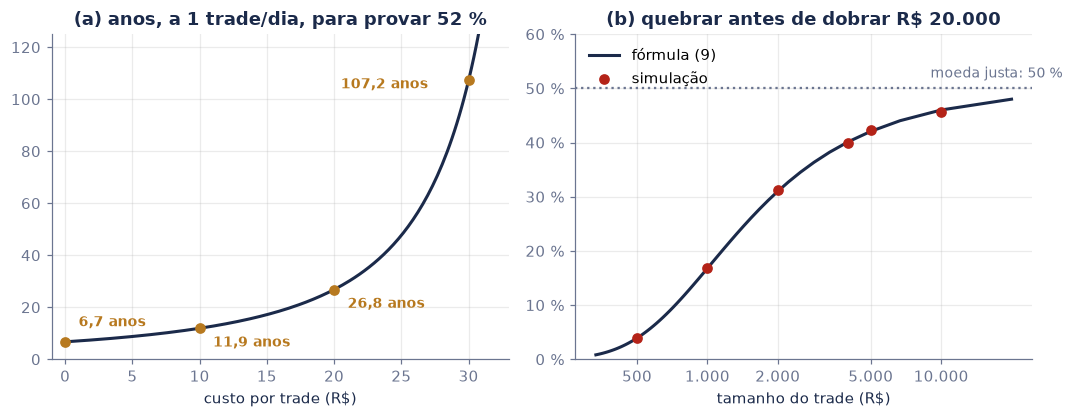

In [19]:
rng_m = np.random.default_rng(52)
linhas = []
for tam in (10_000, 5_000, 4_000, 2_000, 1_000, 500):
    a = 20_000 // tam
    sim, dur = simula_ruina(acerto, a, 2 * a, 20_000, rng_m)
    linhas.append({"tamanho do trade": brl(tam), "unidades a": a, "quebra antes de dobrar (9)": 1 - chega_N(acerto, a, 2 * a), "simulação": 1 - sim, "trades em média": dur})
tam_tab = pd.DataFrame(linhas)
display(tam_tab.style.format({"quebra antes de dobrar (9)": fp(), "simulação": fp(), "trades em média": "{:,.0f}"}, **fmt).hide(axis="index"))
rr = 0.48 / 0.52
assert all(abs(l["quebra antes de dobrar (9)"] - rr ** l["unidades a"] / (1 + rr ** l["unidades a"])) < 1e-12 for l in linhas)
assert all(abs(l["quebra antes de dobrar (9)"] - l["simulação"]) < 0.012 for l in linhas)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.9))
cc = np.linspace(0, 36, 200)
axs[0].plot(cc, (Z95 * sig_t / (mu_t - cc)) ** 2 / 252, color=NAVY, lw=2)
for c in (0, 10, 20, 30):
    v = (Z95 * sig_t / (mu_t - c)) ** 2 / 252; axs[0].scatter([c], [v], color=GOLD, zorder=3); axs[0].annotate(f"{br(v, 1)} anos", (c, v), {0: (1, v + 6), 10: (11, v - 7), 20: (21, v - 7), 30: (20.5, v - 3)}[c], color=GOLD, weight="bold", fontsize=9)
axs[0].set(title="(a) anos, a 1 trade/dia, para provar 52 %", xlabel="custo por trade (R$)", ylim=(0, 125), xlim=(-1, 33))
aa = np.arange(1, 61)
axs[1].plot(20_000 / aa, [1 - chega_N(acerto, a, 2 * a) for a in aa], color=NAVY, lw=2, label="fórmula (9)")
axs[1].scatter([20_000 / l["unidades a"] for l in linhas], [l["simulação"] for l in linhas], color=RED, zorder=3, label="simulação")
axs[1].axhline(0.5, color=GREY, ls=":"); axs[1].text(9000, 0.52, "moeda justa: 50 %", color=GREY, fontsize=9)
axs[1].set(title="(b) quebrar antes de dobrar R$ 20.000", xlabel="tamanho do trade (R$)", xscale="log", ylim=(0, 0.6))
axs[1].set_xticks([500, 1000, 2000, 5000, 10000], ["500", "1.000", "2.000", "5.000", "10.000"]); axs[1].minorticks_off()
axs[1].yaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f} %"); axs[1].legend(frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

**Leitura.** Uma vantagem de 2 pontos na taxa de acerto é real e pequena: a deriva de R\$ 40 por trade é 25 vezes menor que o risco de R\$ 1.000. São precisos **624 trades** para ela empatar com o ruído e **1.688** para aparecer com 95 % de confiança: quase 7 anos a um trade por dia. Depois de 252 trades (um ano), um operador **sem nenhuma habilidade** mostra 52 % ou mais em 1 de cada 4 vezes. Uma mesa que avalia operador por um ano de resultado está premiando a sorte.

O custo é o que mata: R\$ 20 por trade cortam a deriva pela metade e **quadruplicam** o tempo para provar a habilidade (a eq. (8) tem $\mu$ ao quadrado no denominador). E o tamanho da posição é a ruína do jogador ao contrário: com vantagem, operar pequeno é o certo. Com trades de R\$ 10.000 (2 unidades), o operador de 52 % quebra antes de dobrar em 46 % das vezes; com trades de R\$ 500, em 4 %. Com vantagem, mais passos são aliados; sem ela, inimigos.

## 11. O que este modelo não vê

1. **Preços se movem em porcentagem.** O passeio do vídeo soma \$1 por passo; preços de verdade multiplicam: um ganho de 10 % seguido de uma perda de 10 % não volta ao início. Por isso o modelo de mercado usa o log do preço (seções 8 e 9), e a volatilidade cobra $\sigma^2/2$ do retorno composto (seção 9).
2. **Fases calmas e agitadas.** A moeda tem sempre o mesmo risco por passo. O Ibovespa não: o retorno absoluto tem memória de meses (seção 8). O teste de Lo & MacKinlay só funciona com a correção para isso.
3. **Saltos.** 15/01/1999 (+33,4 %), 10/09/1998 (−15,8 %), 12/03/2020 (−14,8 %): numa normal com a volatilidade diária do Ibovespa, dias assim não deveriam acontecer nunca. Caudas gordas mudam o risco de ruína e o VaR.
4. **A deriva não é conhecida, nem constante.** O vídeo sabe que $p = 19/37$. O investidor não sabe o prêmio da bolsa, e a seção 9 mostra que nem 31 anos de dados o revelam. O prêmio também muda com os juros, a inflação e o risco do país.
5. **Memória não linear.** Não rejeitar o passeio aleatório nos retornos não exclui padrões que o teste da razão de variâncias não mede (na volatilidade, nas caudas, entre ativos).

### Para praticar (respostas na célula seguinte)

1. Uma moeda tem $p = 0{,}55$. Qual a deriva, o desvio de um passo e o $n^*$? Depois de 100 lances, qual a chance de estar abaixo do início, pela eq. (7)?
2. Pela eq. (5), qual a chance de um passeio justo de 400 passos chegar a +40 em algum momento?
3. Uma roleta americana tem 38 casas (o vermelho ganha com 18/38). Com R\$ 100 e apostas de R\$ 10, qual a chance de dobrar a banca, pela eq. (9)?
4. Uma estratégia tem Sharpe de 0,5 ao ano (deriva/volatilidade). Quantos anos para o resultado aparecer com 95 % de confiança (unicaudal)?
5. Num dia, o $VR(2)$ de um ativo é 1,10. Qual a autocorrelação de primeira ordem implícita pela eq. (10)?

In [20]:
q1 = 0.55; m1 = 2 * q1 - 1; s1 = math.sqrt(1 - m1 ** 2)
print("1)", f"μ = {br(m1, 2)}, σ = {br(s1, 4)}, n* = {br((s1 / m1) ** 2, 1)}; abaixo do início em 100 lances ≈ Φ(−{br(m1 * 10 / s1, 3)}) = {pct(Phi(-m1 * 10 / s1))} (exato: {pct(1 - binom_cauda(50, 100, q1))}, contando só S < 0)")
p2 = binom_cauda(220, 400, 0.5) + binom_cauda(221, 400, 0.5)
print("2)", f"P(S ≥ 40) + P(S > 40) = {pct(p2)}; normal: 2[1 − Φ(40/20)] = {pct(2 * (1 - Phi(2)))}")
print("3)", f"r = 20/18, a = 10, N = 20: {pct(chega_N(18 / 38, 10, 20))} (na europeia, {pct(chega_N(18 / 37, 10, 20))})")
print("4)", f"n = (1,645/0,5)² = {br((Z95 / 0.5) ** 2, 1)} anos")
print("5)", f"VR(2) = 1 + ρ₁ → ρ₁ = 0,10; com 2.500 dias, z ingênuo = √2500 × 0,10 = {br(math.sqrt(2500) * 0.10, 1)}; com o θ̂(2) do Ibovespa, z* = {br(math.sqrt(2500) * 0.10 / math.sqrt((razao_variancias(r, 2)[1] / razao_variancias(r, 2)[2]) ** 2), 2)}")

1) μ = 0,10, σ = 0,9950, n* = 99,0; abaixo do início em 100 lances ≈ Φ(−1,005) = 15,7 % (exato: 13,5 %, contando só S < 0)
2) P(S ≥ 40) + P(S > 40) = 4,6 %; normal: 2[1 − Φ(40/20)] = 4,6 %
3) r = 20/18, a = 10, N = 20: 25,9 % (na europeia, 36,8 %)
4) n = (1,645/0,5)² = 10,8 anos
5) VR(2) = 1 + ρ₁ → ρ₁ = 0,10; com 2.500 dias, z ingênuo = √2500 × 0,10 = 5,0; com o θ̂(2) do Ibovespa, z* = 2,16


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Deriva de um passo | $\mu = p(+1) + (1-p)(-1) = 2p-1$ | $1/37$ = +2,7¢ por passo |
| (2) Risco de um passo | $\sigma^2 = 1 - \mu^2$ | $1368/1369$ |
| (3) Soma de $n$ passos | $\mathbb{E}[S_n] = n\mu$, $\mathrm{DP}[S_n] = \sigma\sqrt{n}$ | +\$108 ± \$63 em 4.000 passos |
| (4) Arco-seno | $\Pr(F_n \le x) \to \frac{2}{\pi}\arcsin\sqrt{x}$ | 82 % do tempo acima: 28 % dos passeios justos |
| (5) Reflexão | $\Pr(\max S \ge a) = \Pr(S_n \ge a) + \Pr(S_n > a)$ | máxima de +\$31: um terço dos passeios |
| (6) Maior sequência | $R_n/\log_2 n \to 1$ | 11 lances iguais em 1.000 |
| (7) Abaixo do início | $\Pr(S_n<0) \approx \Phi(-\mu\sqrt{n}/\sigma)$ | 43 %, 20 %, 4 % |
| (8) A corrida | $n^* = (\sigma/\mu)^2$, $n_z = (z\sigma/\mu)^2$ | 1.368 e 3.701 passos; 624 e 1.688 trades |
| (9) Ruína do jogador | $(1-r^a)/(1-r^N)$ | R\$ 100 → R\$ 200 no vermelho: 48,6 % ou 0,45 % |
| (10) Razão de variâncias | $VR(q) = 1 + 2\sum(1-k/q)\rho_k$ | Ibovespa: entre 0,88 e 1,01 |
| (11) $z^*$ robusto | Lo & MacKinlay (1988) | nenhum rejeita a 5 % |
| (12) Abaixo do CDI | $\Phi(-\mu\sqrt{T}/\sigma)$ | deriva de −1,8 % ao ano, σ de 31 % |

### Referências

- BACHELIER, L. Théorie de la spéculation. *Annales scientifiques de l'École Normale Supérieure*, 3e série, v. 17, p. 21–86, 1900.
- ERDŐS, P.; RÉNYI, A. On a new law of large numbers. *Journal d'Analyse Mathématique*, v. 23, p. 103–111, 1970.
- FAMA, E. F. The behavior of stock-market prices. *Journal of Business*, v. 38, n. 1, p. 34–105, 1965.
- FAMA, E. F. Efficient capital markets: a review of theory and empirical work. *Journal of Finance*, v. 25, n. 2, p. 383–417, 1970.
- FELLER, W. *An Introduction to Probability Theory and Its Applications*, v. 1, 3. ed. New York: Wiley, 1968.
- KÜNSCH, H. R. The jackknife and the bootstrap for general stationary observations. *Annals of Statistics*, v. 17, n. 3, p. 1217–1241, 1989.
- LO, A. W.; MACKINLAY, A. C. Stock market prices do not follow random walks: evidence from a simple specification test. *Review of Financial Studies*, v. 1, n. 1, p. 41–66, 1988.
- MERTON, R. C. On estimating the expected return on the market: an exploratory investigation. *Journal of Financial Economics*, v. 8, n. 4, p. 323–361, 1980.
- SAMUELSON, P. A. Proof that properly anticipated prices fluctuate randomly. *Industrial Management Review*, v. 6, n. 2, p. 41–49, 1965.
- SCHILLING, M. F. The longest run of heads. *The College Mathematics Journal*, v. 21, n. 3, p. 196–207, 1990.
- Dados: Yahoo Finance (`^BVSP`); Banco Central do Brasil, SGS, série 12 (CDI).

*Gabriel Pires · [gabrielppires.com](https://gabrielppires.com) · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · O vídeo é inspirado em* Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Preços simulados nas seções 0 a 7; dados reais do Ibovespa e do CDI nas seções 8 e 9. Só educação, não é recomendação de investimento.*